
# Weight Initialization in Neural Networks — PyTorch Lab

### Topics
1. Zero Initialization
2. Constant Initialization
3. Naive Random Initialization
4. Xavier / Glorot Initialization
5. He / Kaiming Initialization
6. Fair accuracy comparison of all initialization methods

### Learning objectives
By the end of this notebook, students should be able to:

- explain why **zero and constant weight initialization are poor choices** for hidden layers;
- understand that simply saying “random initialization” is not enough — the **scale of random weights matters**;
- calculate Xavier and He initialization scales numerically;
- use PyTorch's built-in initialization functions;
- experimentally compare different initialization methods.

> **Important:** Xavier and He are also random initializers.  
> In this notebook, **“Naive Random”** means random weights chosen with an intentionally poor scale, so students can see why *properly scaled* random initialization matters.


PyTorch version: 2.11.0+cpu
Training samples: 1500
Test samples: 500


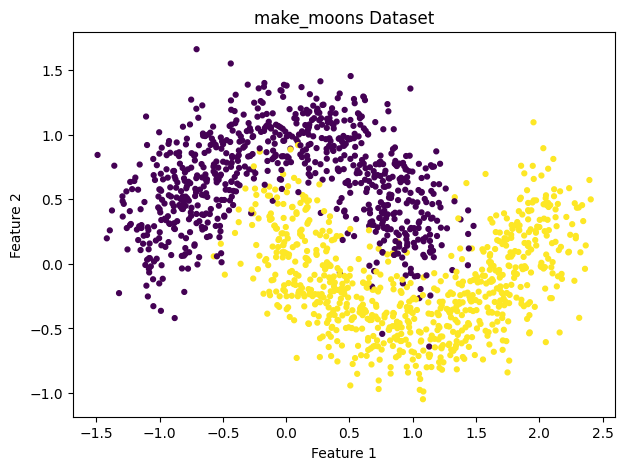

In [1]:

# Imports
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(42)

print("PyTorch version:", torch.__version__)


# Create a nonlinear binary-classification dataset
X, y = make_moons(
    n_samples=2000,
    noise=0.22,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])


plt.figure(figsize=(7, 5))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=12)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("make_moons Dataset")
plt.show()



---
# 1.  Weight Initialization ?

For a neuron:

$$
z=w_1x_1+w_2x_2+\cdots+w_nx_n+b
$$

Before training begins, we must choose initial values for the weights.


##   Implementation
We will use this ReLU network:

$$
2 \rightarrow 64 \rightarrow 64 \rightarrow 64 \rightarrow 64 \rightarrow 2
$$

The network is intentionally somewhat deep so that differences between initialization methods are easy to observe.


In [ ]:

# Convert the normalized data to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t  = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t  = torch.tensor(y_test, dtype=torch.long)

class DeepMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 64),
            nn.ReLU(),

            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.network(x)

model = DeepMLP()
print(model)


# ------------------------------------------------------------
# Helper functions used after each initialization method
# ------------------------------------------------------------

def show_initial_weights(model, rows=5):
    """
    Show a small sample of the FIRST layer weights before training.
    The first layer has 2 inputs, so each row contains 2 weights.
    """
    W = model.network[0].weight.detach().cpu()

    print("Initial first-layer weights")
    print(f"(first {rows} neurons × {W.shape[1]} input weights):")
    print(W[:rows])

    print("\nFirst-layer weight mean:",
          round(W.mean().item(), 6))
    print("First-layer weight standard deviation:",
          round(W.std(unbiased=False).item(), 6))


def train_initialized_model(model, epochs=100, learning_rate=0.03):
    """
    Train a model that has ALREADY been initialized.
    Returns training history and test accuracy.
    """
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

    history = []

    for epoch in range(epochs):
        model.train()

        logits = model(X_train_t)
        loss = loss_fn(logits, y_train_t)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        history.append(loss.item())

    model.eval()

    with torch.no_grad():
        test_logits = model(X_test_t)
        predictions = test_logits.argmax(dim=1)
        accuracy = (predictions == y_test_t).float().mean().item()

    return history, accuracy


def print_training_result(method, history, accuracy):
    print(f"\nResult after training with {method} initialization")
    print("-" * 55)
    print(f"Final training loss : {history[-1]:.6f}")
    print(f"Test accuracy       : {accuracy * 100:.2f}%")


DeepMLP(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): ReLU()
    (8): Linear(in_features=64, out_features=2, bias=True)
  )
)



---
# 2. Zero Initialization

In zero initialization:

$$
W=0
$$

for every weight.


### Why Zero Initialization Is Worse with ReLU

With zero initialization, all weights start as:

$$
W = 0
$$

So the pre-activation of a hidden neuron can become:

$$
z = Wx + b = 0
$$

For ReLU, the gradient at \(z = 0\) is typically taken as:

$$
\frac{d\,\mathrm{ReLU}(z)}{dz} = 0
$$

Therefore, during backpropagation, the gradient may not pass through that neuron.

The weight update is:

$$
W_{\text{new}} = W_{\text{old}} - \eta \frac{\partial L}{\partial W}
$$

If the gradient is zero, the weights do not update.

**In short:**

`Zero weights → z = 0 → ReLU gradient = 0 → no useful weight update → learning can stop`


In [ ]:
def initialize_zero(model):
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.zeros_(layer.weight)
            nn.init.zeros_(layer.bias)

# Use the same seed for a fair/reproducible demonstration
set_seed(7)

zero_model = DeepMLP()
initialize_zero(zero_model)

# 1) Show weights immediately AFTER initialization and BEFORE training
show_initial_weights(zero_model, rows=5)

# 2) Train and show the result for this initialization
zero_history, zero_accuracy = train_initialized_model(zero_model)
print_training_result("Zero", zero_history, zero_accuracy)


Initial first-layer weights
(first 5 neurons × 2 input weights):
tensor([[0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.]])

First-layer weight mean: 0.0
First-layer weight standard deviation: 0.0



Result after training with Zero initialization
-------------------------------------------------------
Final training loss : 0.693147
Test accuracy       : 50.00%


# 3. Constant Initialization

* In constant initialization, every weight is initialized with the same constant value:

$$
W = c
$$

* For example:

$$
W = 0.5
$$

* The main problem is that all neurons in the same layer start with identical weights.

* Because they receive the same type of input with the same weights, they produce similar outputs and receive the same gradients during backpropagation.

* Therefore, their weights remain identical even after updating.

* This is called the **symmetry problem**.

* Suppose a hidden layer has 5 neurons. Ideally, different neurons should learn different patterns, for example:

  * one neuron may learn an edge,
  * another may learn a curve,
  * another may learn a different combination of features.

* Ideally, different neurons should learn different features.

* But with constant initialization, many neurons may behave like copies of one another.

* So instead of learning several different features, the layer may effectively learn only one repeated feature.

**In short:**

`Same constant weights → same neuron behavior → same gradients → neurons remain identical → reduced learning capacity`


In [ ]:
def initialize_constant(model, value=0.5):
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.constant_(layer.weight, value)
            nn.init.zeros_(layer.bias)

# Use the same seed for a fair/reproducible demonstration
set_seed(7)

constant_model = DeepMLP()
initialize_constant(constant_model, value=0.5)

# 1) Show weights immediately AFTER initialization and BEFORE training
show_initial_weights(constant_model, rows=5)

# 2) Train and show the result for this initialization
constant_history, constant_accuracy = train_initialized_model(constant_model)
print_training_result("Constant", constant_history, constant_accuracy)


Initial first-layer weights
(first 5 neurons × 2 input weights):
tensor([[0.5000, 0.5000],
        [0.5000, 0.5000],
        [0.5000, 0.5000],
        [0.5000, 0.5000],
        [0.5000, 0.5000]])

First-layer weight mean: 0.5
First-layer weight standard deviation: 0.0



Result after training with Constant initialization
-------------------------------------------------------
Final training loss : 0.693151
Test accuracy       : 50.00%



---
# 4.  Random Initialization

Random initialization solves the symmetry problem because different neurons start with different weights.

But there is another question:


* If the random weights are **too small**:

  * activations can become very small,
  * gradients can also shrink as they move backward through many layers,
  * this may cause the **vanishing gradient problem**,
  * and learning can become very slow.

* If the random weights are **too large**:

  * activations can become very large,
  * gradients can grow excessively,
  * this may cause **exploding gradients** and unstable training.





**In short:**

`Random initialization breaks symmetry, but badly scaled random weights can cause vanishing gradients, exploding gradients, or unstable training.`

This is why more systematic methods such as **Xavier initialization** and **He initialization** are preferred.


In [ ]:
def initialize_naive_random(model, std=0.005):
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.normal_(layer.weight, mean=0.0, std=std)
            nn.init.zeros_(layer.bias)

# Use the same seed for a fair/reproducible demonstration
set_seed(7)

random_model = DeepMLP()
initialize_naive_random(random_model, std=0.005)

# 1) Show weights immediately AFTER initialization and BEFORE training
show_initial_weights(random_model, rows=5)

# 2) Train and show the result for this initialization
random_history, random_accuracy = train_initialized_model(random_model)
print_training_result("Naive Random", random_history, random_accuracy)


Initial first-layer weights
(first 5 neurons × 2 input weights):
tensor([[-0.0033,  0.0015],
        [-0.0041, -0.0076],
        [ 0.0037, -0.0006],
        [-0.0007, -0.0058],
        [-0.0008, -0.0051]])

First-layer weight mean: -0.000554
First-layer weight standard deviation: 0.005279



Result after training with Naive Random initialization
-------------------------------------------------------
Final training loss : 0.693147
Test accuracy       : 50.20%


# 5. Xavier / Glorot Initialization

Xavier initialization chooses the weight scale using both:

* `fan_in` = number of inputs entering a neuron
* `fan_out` = number of outputs leaving the layer

It is especially associated with **tanh** and **sigmoid-like** activations, although it can also be tested with other activations.

Xavier initialization works well because it chooses the random weight scale according to the number of neurons connected to a layer.

Instead of using arbitrary random values, it controls the variance of the weights so that the activations do not become too large or too small as they move through the network.

For **Xavier Normal**:

$$
\sigma = \sqrt{\frac{2}{\mathrm{fan}_{in}+\mathrm{fan}_{out}}}
$$

where $\sigma$ is the **standard deviation** used to generate the random weights.

---

### Numerical Example

Suppose a layer has:

$$
\mathrm{fan}_{in}=100
$$

and

$$
\mathrm{fan}_{out}=100
$$

Then:

$$
\sigma = \sqrt{\frac{2}{100+100}}
$$

$$
\sigma = \sqrt{\frac{2}{200}}
$$

$$
\sigma = \sqrt{0.01}
$$

$$
\sigma = 0.1
$$

So the weights can be randomly sampled from a normal distribution:

$$
W \sim \mathcal{N}(0,0.1^2)
$$

One possible set of 5 randomly initialized weights could be:

$$
W=[0.04,\,-0.08,\,0.12,\,-0.03,\,0.07]
$$

Notice that the weights are:

* random, so symmetry is broken
* both positive and negative
* centered around **0**
* generally **close to 0** because the standard deviation is only $0.1$

The weights are kept relatively small so that:

$$
z = Wx+b
$$

does not become extremely large.

This is particularly useful for **sigmoid** and **tanh**, because very large positive or negative values of $z$ can push these activation functions into their saturation regions, where gradients become very small.

**In short:**

`fan_in + fan_out → determine standard deviation → generate properly scaled random weights → keep z at a reasonable scale → reduce vanishing/exploding activations and gradients`


In [ ]:
def initialize_xavier(model):
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            # Xavier NORMAL matches the formula explained above
            nn.init.xavier_normal_(layer.weight)
            nn.init.zeros_(layer.bias)

# Use the same seed for a fair/reproducible demonstration
set_seed(7)

xavier_model = DeepMLP()
initialize_xavier(xavier_model)

# 1) Show weights immediately AFTER initialization and BEFORE training
show_initial_weights(xavier_model, rows=5)

# 2) Train and show the result for this initialization
xavier_history, xavier_accuracy = train_initialized_model(xavier_model)
print_training_result("Xavier", xavier_history, xavier_accuracy)


Initial first-layer weights
(first 5 neurons × 2 input weights):
tensor([[-0.1166,  0.0530],
        [-0.1415, -0.2656],
        [ 0.1288, -0.0202],
        [-0.0236, -0.2017],
        [-0.0291, -0.1779]])

First-layer weight mean: -0.019302
First-layer weight standard deviation: 0.1838



Result after training with Xavier initialization
-------------------------------------------------------
Final training loss : 0.493034
Test accuracy       : 82.60%


# 6. He Initialization

He initialization chooses the weight scale mainly using:

* `fan_in` = number of inputs entering a neuron

It is especially designed for **ReLU** and ReLU-like activation functions.

The main idea is that ReLU sets all negative pre-activations to zero:

$$
\mathrm{ReLU}(z)=\max(0,z)
$$

Because roughly half of the pre-activations may become zero, some of the signal is lost after passing through ReLU.

He initialization compensates for this by using a slightly larger weight variance than Xavier.

For **He Normal**:

$$
\sigma = \sqrt{\frac{2}{\mathrm{fan}_{in}}}
$$

where $\sigma$ is the **standard deviation** used to generate the random weights.

---

### Numerical Example

Suppose a layer has:

$$
\mathrm{fan}_{in}=100
$$

Then:

$$
\sigma = \sqrt{\frac{2}{100}}
$$

$$
\sigma = \sqrt{0.02}
$$

$$
\sigma \approx 0.141
$$

So the weights can be randomly sampled from:

$$
W \sim \mathcal{N}(0,0.141^2)
$$

One possible set of 5 randomly initialized weights could be:

$$
W=[0.06,\,-0.13,\,0.18,\,-0.05,\,0.11]
$$

Notice that the weights are:

* random, so symmetry is broken
* both positive and negative
* centered around **0**

* slightly more spread out than Xavier weights

For comparison, if Xavier gave:

$$
\sigma = 0.1
$$

then He gives:

$$
\sigma \approx 0.141
$$

So He uses a **larger spread of weights**.

This does **not** mean that He tries to make more weights positive.

The larger spread means both positive and negative weights can have somewhat larger magnitudes.

Because:

$$
z = Wx+b
$$

a larger spread in $W$ produces an appropriately larger spread in the pre-activations $z$.

Then ReLU removes the negative $z$ values:

$$
z<0 \rightarrow 0
$$

while the positive $z$ values survive with enough magnitude to carry useful information to the next layer.

Therefore, He initialization helps keep the activation scale reasonably stable across many ReLU layers.

**In short:**

`fan_in → determine standard deviation → slightly larger random weight spread → ReLU removes negative activations → surviving positive activations still have useful magnitude`


In [ ]:
def initialize_he(model):
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(
                layer.weight,
                mode="fan_in",
                nonlinearity="relu"
            )
            nn.init.zeros_(layer.bias)

# Use the same seed for a fair/reproducible demonstration
set_seed(7)

he_model = DeepMLP()
initialize_he(he_model)

# 1) Show weights immediately AFTER initialization and BEFORE training
show_initial_weights(he_model, rows=5)

# 2) Train and show the result for this initialization
he_history, he_accuracy = train_initialized_model(he_model)
print_training_result("He", he_history, he_accuracy)


Initial first-layer weights
(first 5 neurons × 2 input weights):
tensor([[-0.6696,  0.3045],
        [-0.8128, -1.5256],
        [ 0.7397, -0.1161],
        [-0.1356, -1.1588],
        [-0.1673, -1.0218]])

First-layer weight mean: -0.11088
First-layer weight standard deviation: 1.055848



Result after training with He initialization
-------------------------------------------------------
Final training loss : 0.274678
Test accuracy       : 87.80%



---
# 7. Compare the Initializers Fairly

To make the comparison meaningful, we keep the following identical:

- dataset;
- network architecture;
- loss function;
- optimizer;
- learning rate;
- number of epochs;
- random seed.

Only the **initialization method** changes.

Each initializer above already shows its weights **before training** and its individual training result. The table below repeats the experiment from fresh models for a side-by-side comparison.

We use full-batch SGD for a fixed training budget. This makes the effect of initialization especially easy to see.

### Expected qualitative result

$$
\boxed{\text{He / Xavier} > \text{Zero / Constant / Naive Random}}
$$

The exact percentages can vary slightly across software or hardware versions, but the main pattern should remain clear with this setup.


In [ ]:

def apply_initialization(model, method):
    if method == "Zero":
        initialize_zero(model)

    elif method == "Constant":
        initialize_constant(model, value=0.5)

    elif method == "Naive Random":
        initialize_naive_random(model, std=0.005)

    elif method == "Xavier":
        initialize_xavier(model)

    elif method == "He":
        initialize_he(model)

    else:
        raise ValueError("Unknown initialization method")


In [ ]:

def train_model(method, epochs=100, learning_rate=0.03):
    # Reset the seed so every method gets the same experimental conditions.
    set_seed(7)

    model = DeepMLP()
    apply_initialization(model, method)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

    history = []

    for epoch in range(epochs):
        model.train()

        logits = model(X_train_t)
        loss = loss_fn(logits, y_train_t)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        history.append(loss.item())

    model.eval()

    with torch.no_grad():
        test_logits = model(X_test_t)
        predictions = test_logits.argmax(dim=1)
        accuracy = (predictions == y_test_t).float().mean().item()

    return model, history, accuracy


In [ ]:

methods = [
    "Zero",
    "Constant",
    "Naive Random",
    "Xavier",
    "He"
]

results = []
histories = {}

for method in methods:
    trained_model, history, accuracy = train_model(method)

    histories[method] = history

    results.append({
        "Initialization": method,
        "Test Accuracy": accuracy,
        "Test Accuracy (%)": 100 * accuracy
    })

results_df = pd.DataFrame(results)
results_df


,Initialization,Test Accuracy,Test Accuracy (%)
0,Zero,0.500,50.000000
1,Constant,0.500,50.000000
2,Naive Random,0.502,50.199997
3,Xavier,0.826,82.599998
4,He,0.878,87.800002


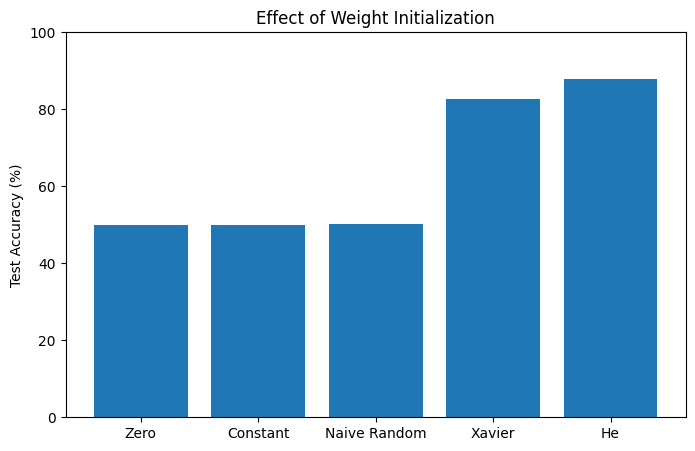

In [ ]:

# Plot test accuracy
plt.figure(figsize=(8, 5))
plt.bar(
    results_df["Initialization"],
    results_df["Test Accuracy (%)"]
)
plt.ylabel("Test Accuracy (%)")
plt.title("Effect of Weight Initialization")
plt.ylim(0, 100)
plt.show()
